# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:**
- **Устройство:** Google Colab, GPU Tesla T4 (15 GB)
- **Модель:** `yolo26n.pt` (`ultralytics==8.4.216`, лицензия AGPL-3.0)
- **Датасет:** Aquarium Combined v6 (https://universe.roboflow.com/brad-dwyer/aquarium-combined/dataset/6, лицензия CC BY 4.0)
- **Бонусы:** `6.3`, `6.4`, `6.5` выполнены полностью; код для `6.2` (RT-DETR) написан и проверен в `FAST_MODE`, но в финальном прогоне `FAST_MODE = False` не доведён до конца из-за ограничения по времени
- **Источники:** документация Ultralytics, код семинара 5–6 (обучение YOLO и `to_yolo`)
- **Нерешённые задачи:** бонусное задание `6.1` не выполнялось

In [44]:
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [45]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.216, torch 2.14.1+cu130, device: Tesla T4


In [46]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [47]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [48]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)

params_count = sum(p.numel() for p in model_coco.model.parameters())
sha256_hash = hashlib.sha256(weights_path.read_bytes()).hexdigest()
size_mb = round(weights_path.stat().st_size / (1024 ** 2), 2)
n_classes_coco = len(model_coco.names)

dummy_img = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
for _ in range(5):
    model_coco.predict(dummy_img, imgsz=IMGSZ, device=DEVICE, verbose=False)

n_runs = 20
if torch.cuda.is_available():
    torch.cuda.synchronize()
t0 = time.perf_counter()
for _ in range(n_runs):
    model_coco.predict(dummy_img, imgsz=IMGSZ, device=DEVICE, verbose=False)
if torch.cuda.is_available():
    torch.cuda.synchronize()
latency_ms = round((time.perf_counter() - t0) * 1000 / n_runs, 3)

MODEL_INFO = {
    'ultralytics': ultralytics.__version__,
    'weights': WEIGHTS,
    'sha256': sha256_hash,
    'size_mb': size_mb,
    'params': params_count,
    'n_classes_coco': n_classes_coco,
    'latency_ms': latency_ms,
}

In [49]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.29,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 10.802}

**Ответ:** yolo26n.pt (2.57 млн параметров, 5.29 МБ, 10.8 мс на T4 при 640x640) выбрана под небольшой датасет (448 train-картинок) и бюджет часа: она меньше переобучается и учится за ~18 мин. Соседняя yolo26s.pt почти в 4 раза тяжелее (примерно 9.5 млн параметров), точнее на COCO (примерно 47–48% против примерно 40%), но в 1.5–2 раза медленнее. Лицензия ultralytics - AGPL-3.0: бесплатно для учёбы и открытого кода (с раскрытием исходников), для закрытого коммерческого продукта нужна платная лицензия

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [50]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    backbone = sum(p.numel() for m in layers[:n_backbone] for p in m.parameters())
    neck = sum(p.numel() for m in layers[n_backbone:-1] for p in m.parameters())
    head = sum(p.numel() for p in layers[-1].parameters())
    return {'backbone': backbone, 'neck': neck, 'head': head}


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    feat_shapes = []

    def hook(module, inp, output):
        feats = inp[0]
        if isinstance(feats, (list, tuple)):
            feat_shapes.extend(tuple(f.shape) for f in feats)
        else:
            feat_shapes.append(tuple(feats.shape))

    det_model.eval()
    p = next(det_model.parameters())
    x = torch.zeros(1, 3, imgsz, imgsz, device=p.device, dtype=p.dtype)
    handle = det_model.model[-1].register_forward_hook(hook)
    try:
        with torch.no_grad():
            out = det_model(x)
    finally:
        handle.remove()
    return feat_shapes, out


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [51]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [52]:
print('выход модели:', shapes(out))

выход модели: [(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Ответ:** Backbone (53%, 1.37 млн параметров) извлекает признаки, neck (35%, 897 тыс.) объединяет три масштаба (страйды 8, 16, 32), а head Detect (12%, 310 тыс.) в каждой точке предсказывает 4 координаты бокса и 80 классов. Модель anchor-free, так как предсказывает расстояния от центра клетки до сторон бокса без якорных рамок; число 8400 при входе 640 - это $80^2 + 40^2 + 20^2$. Ветка one2many даёт основной сигнал при обучении, а one2one учится выдавать ровно один бокс на объект и используется на инференсе, поэтому NMS не нужен

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [53]:
import zipfile

DATASET_NAME = 'Aquarium Combined v6 (https://universe.roboflow.com/brad-dwyer/aquarium-combined/dataset/6, CC BY 4.0)'
RAW_DIR = DATA_ROOT / 'aquarium_coco'

if not (RAW_DIR / 'train' / '_annotations.coco.json').exists():
    zips = sorted(Path('/content/drive/MyDrive').glob('*.zip'))
    assert zips, 'Загрузите zip-архив датасета в текущую папку Colab!'
    zip_path = zips[0]
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(RAW_DIR)
    print(f'Распакован архив: {zip_path} -> {RAW_DIR}')

if not (RAW_DIR / 'train' / '_annotations.coco.json').exists():
    found = list(RAW_DIR.rglob('_annotations.coco.json'))
    assert found, f'Не найден _annotations.coco.json внутри {RAW_DIR}'
    RAW_DIR = found[0].parent.parent

split_map = {'train': 'train', 'valid': 'val', 'test': 'test'}

used_cat_ids = set()
raw_cats = {}
for src_split in split_map:
    ann_path = RAW_DIR / src_split / '_annotations.coco.json'
    if not ann_path.exists():
        continue
    coco = json.loads(ann_path.read_text(encoding='utf-8'))
    for c in coco['categories']:
        raw_cats[c['id']] = c['name']
    for a in coco['annotations']:
        used_cat_ids.add(a['category_id'])

sorted_cat_ids = sorted(used_cat_ids)
cat_id_to_idx = {cid: i for i, cid in enumerate(sorted_cat_ids)}
CLASSES = [raw_cats[cid] for cid in sorted_cat_ids]

records = {}
n_clipped = 0
n_zero_area = 0

for src_split, dst_split in split_map.items():
    split_dir = RAW_DIR / src_split
    ann_path = split_dir / '_annotations.coco.json'
    if not ann_path.exists():
        continue
    coco = json.loads(ann_path.read_text(encoding='utf-8'))
    anns_by_img = {img['id']: [] for img in coco['images']}
    for a in coco['annotations']:
        if a['image_id'] in anns_by_img and a['category_id'] in cat_id_to_idx:
            anns_by_img[a['image_id']].append(a)

    split_recs = []
    for img in coco['images']:
        img_path = split_dir / img['file_name']
        if not img_path.exists():
            continue
        with Image.open(img_path) as im:
            w, h = im.size

        boxes, labels = [], []
        for a in anns_by_img[img['id']]:
            x, y, bw, bh = a['bbox']
            x1, y1, x2, y2 = float(x), float(y), float(x + bw), float(y + bh)
            if x1 < 0 or y1 < 0 or x2 > w or y2 > h:
                n_clipped += 1
                x1, x2 = np.clip([x1, x2], 0.0, float(w))
                y1, y2 = np.clip([y1, y2], 0.0, float(h))
            if x2 <= x1 or y2 <= y1:
                n_zero_area += 1
                continue
            boxes.append([x1, y1, x2, y2])
            labels.append(cat_id_to_idx[a['category_id']])

        split_recs.append(dict(
            image=img_path,
            width=w,
            height=h,
            boxes=np.array(boxes, dtype=np.float32).reshape(-1, 4),
            labels=np.array(labels, dtype=np.int64),
        ))
    records[dst_split] = split_recs

print(f'Классы ({len(CLASSES)}): {CLASSES}')
print(f'Очистка разметки: обрезано по границам={n_clipped}, удалено с нулевой площадью={n_zero_area}')

Классы (7): ['fish', 'jellyfish', 'penguin', 'puffin', 'shark', 'starfish', 'stingray']
Очистка разметки: обрезано по границам=13, удалено с нулевой площадью=2


In [54]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 448, 'val': 127, 'test': 63}

--- Сводка по сплитам ---
train: 448 картинок, 3328 объектов (на картинку: min=0, median=4.0, mean=7.43, max=56, пустых=1)
val  : 127 картинок,  909 объектов (на картинку: min=1, median=4.0, mean=7.16, max=44, пустых=0)
test :  63 картинок,  582 объектов (на картинку: min=1, median=8.0, mean=9.24, max=45, пустых=0)

--- Объекты по классам ---
класс          train     val    test   всего
fish            1965     459     249    2673
jellyfish        385     155     154     694
penguin          330     104      82     516
puffin           175      74      35     284
shark            259      57      36     352
starfish          78      27      11     116
stingray         136      33      15     184

Размеры боксов (train): медианная доля площади=0.740%, мелких (<32x32 px)=0.6%, мелких (<1% площади)=58.7%


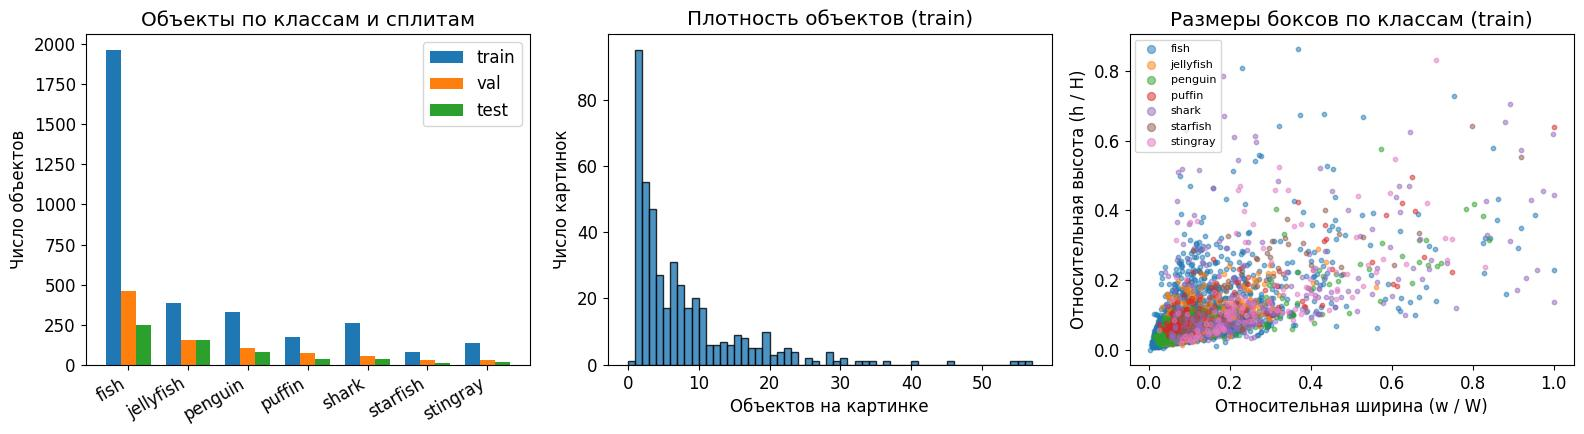

In [55]:
print('--- Сводка по сплитам ---')
for split, recs in records.items():
    counts = [len(r['labels']) for r in recs]
    n_empty = sum(c == 0 for c in counts)
    print(f'{split:<5}: {len(recs):3d} картинок, {sum(counts):4d} объектов '
          f'(на картинку: min={min(counts)}, median={np.median(counts):.1f}, '
          f'mean={np.mean(counts):.2f}, max={max(counts)}, пустых={n_empty})')

print('\n--- Объекты по классам ---')
header = f'{"класс":<12}' + ''.join(f'{s:>8}' for s in records) + f'{"всего":>8}'
print(header)
class_counts = {s: Counter(int(l) for r in recs for l in r['labels']) for s, recs in records.items()}
for i, name in enumerate(CLASSES):
    row = [class_counts[s][i] for s in records]
    print(f'{name:<12}' + ''.join(f'{v:>8d}' for v in row) + f'{sum(row):>8d}')

rel_w, rel_h, rel_area, box_cls, px_area = [], [], [], [], []
for r in records['train']:
    if len(r['boxes']) == 0:
        continue
    bw = r['boxes'][:, 2] - r['boxes'][:, 0]
    bh = r['boxes'][:, 3] - r['boxes'][:, 1]
    rel_w.extend(bw / r['width'])
    rel_h.extend(bh / r['height'])
    rel_area.extend((bw * bh) / (r['width'] * r['height']))
    px_area.extend(bw * bh)
    box_cls.extend(r['labels'])

rel_w, rel_h, rel_area, box_cls, px_area = map(np.array, (rel_w, rel_h, rel_area, box_cls, px_area))
print(f'\nРазмеры боксов (train): медианная доля площади={np.median(rel_area):.3%}, '
      f'мелких (<32x32 px)={(px_area < 32 * 32).mean():.1%}, '
      f'мелких (<1% площади)={(rel_area < 0.01).mean():.1%}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

x = np.arange(len(CLASSES))
width_bar = 0.25
for idx, split in enumerate(records):
    vals = [class_counts[split][i] for i in range(len(CLASSES))]
    axes[0].bar(x + (idx - 1) * width_bar, vals, width_bar, label=split)
axes[0].set_xticks(x)
axes[0].set_xticklabels(CLASSES, rotation=30, ha='right')
axes[0].set_ylabel('Число объектов')
axes[0].set_title('Объекты по классам и сплитам')
axes[0].legend()

objs_per_img = [len(r['labels']) for r in records['train']]
axes[1].hist(objs_per_img, bins=range(0, max(objs_per_img) + 2), edgecolor='black', alpha=0.8)
axes[1].set_xlabel('Объектов на картинке')
axes[1].set_ylabel('Число картинок')
axes[1].set_title('Плотность объектов (train)')

for i, name in enumerate(CLASSES):
    m = box_cls == i
    axes[2].scatter(rel_w[m], rel_h[m], s=10, alpha=0.5, label=name, color=COLORS[i % 10])
axes[2].set_xlabel('Относительная ширина (w / W)')
axes[2].set_ylabel('Относительная высота (h / H)')
axes[2].set_title('Размеры боксов по классам (train)')
axes[2].legend(fontsize=8, markerscale=1.8)

plt.tight_layout()
plt.show()

**Ответ:** Датасет Aquarium Combined v6 (Roboflow, CC BY 4.0): 638 картинок, 7 классов, сплиты train=448 (3328 объектов), val=127 (909), test=63 (582). Виден сильный дисбаланс (fish - 59% объектов в train, starfish - 2.3%), плотные сцены (до 56 объектов на кадр) и много мелких объектов (58.7% меньше 1% площади кадра, медиана 0.74%). При очистке обрезано 13 боксов за границами кадра, удалено 2 нулевых бокса, в train есть 1 пустая картинка

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [56]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)
    lines = []
    for (x1, y1, x2, y2), label in zip(boxes, labels):
        cx = ((x1 + x2) / 2.0) / width
        cy = ((y1 + y2) / 2.0) / height
        bw = (x2 - x1) / width
        bh = (y2 - y1) / height
        lines.append(f'{int(label)} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}')
    return '\n'.join(lines)


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    boxes, labels = [], []
    for line in text.strip().splitlines():
        parts = line.split()
        if not parts:
            continue
        cls = int(parts[0])
        cx, cy, bw, bh = map(float, parts[1:5])
        x1 = (cx - bw / 2.0) * width
        y1 = (cy - bh / 2.0) * height
        x2 = (cx + bw / 2.0) * width
        y2 = (cy + bh / 2.0) * height
        boxes.append([x1, y1, x2, y2])
        labels.append(cls)
    if not boxes:
        return np.zeros((0, 4), dtype=np.float32), np.zeros(0, dtype=np.int64)
    return np.array(boxes, dtype=np.float32), np.array(labels, dtype=np.int64)

In [57]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [58]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    img_dir = YOLO_ROOT / 'images' / split
    lbl_dir = YOLO_ROOT / 'labels' / split
    img_dir.mkdir(parents=True, exist_ok=True)
    lbl_dir.mkdir(parents=True, exist_ok=True)
    for r in recs:
        src = Path(r['image'])
        shutil.copy2(src, img_dir / src.name)
        txt = to_yolo(r['boxes'], r['labels'], r['width'], r['height'])
        (lbl_dir / f'{src.stem}.txt').write_text(txt, encoding='utf-8')


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /content/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: fish
  1: jellyfish
  2: penguin
  3: puffin
  4: shark
  5: starfish
  6: stingray



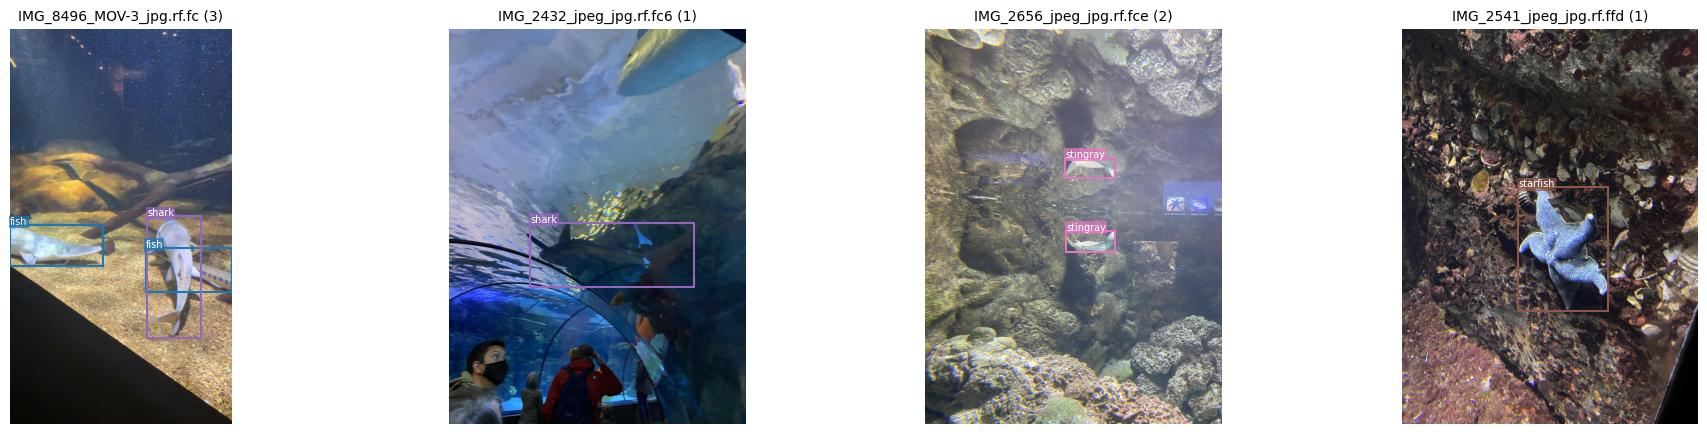

In [59]:
sample_recs = [r for r in train_recs if len(r['boxes']) > 0][:4]
fig, axes = plt.subplots(1, len(sample_recs), figsize=(5 * len(sample_recs), 4.5))
if len(sample_recs) == 1:
    axes = [axes]
for ax, r in zip(axes, sample_recs):
    src = Path(r['image'])
    img_path = YOLO_ROOT / 'images' / 'train' / src.name
    lbl_path = YOLO_ROOT / 'labels' / 'train' / f'{src.stem}.txt'
    img = Image.open(img_path)
    boxes, labels = from_yolo(lbl_path.read_text(encoding='utf-8'), img.width, img.height)
    draw_boxes(ax, img, boxes, labels, CLASSES, title=f'{src.name[:24]} ({len(boxes)})')
plt.tight_layout()
plt.show()

**Ответ:** Тест туда-обратно проверяет обратимость to_yolo/from_yolo, точность до 6 знаков и пустые разметки. Он не поймает симметричную путаницу осей/ширины-высоты, сдвиг индексов классов или несоответствие файлов картинок и .txt - это проверяется только глазами на картинках

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

Топ-10 классов COCO на test: [('bird', 31), ('person', 14), ('kite', 5), ('bear', 2), ('cat', 1), ('umbrella', 1), ('orange', 1), ('vase', 1), ('sports ball', 1), ('surfboard', 1)]
Совпадающие классы с COCO: {}
COCO mAP50 на test: 0.0000


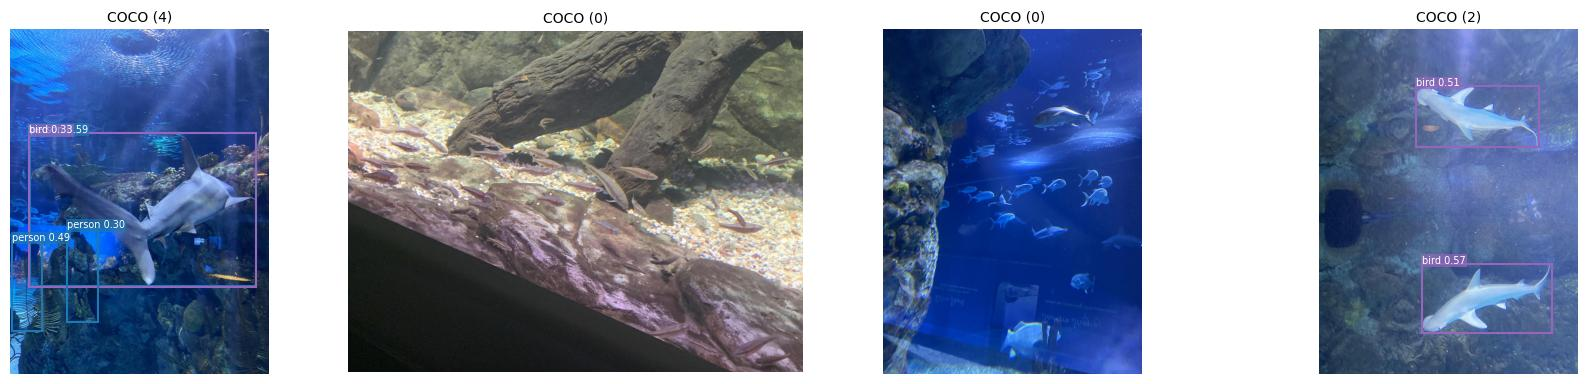

In [60]:
coco_raw_preds = predict_records(model_coco, records[FINAL_SPLIT], conf=0.25)
coco_class_counts = Counter(model_coco.names[int(l)] for p in coco_raw_preds for l in p['labels'])
print(f'Топ-10 классов COCO на {FINAL_SPLIT}:', coco_class_counts.most_common(10))

coco_to_ours = {int(cid): CLASSES.index(name) for cid, name in model_coco.names.items() if name in CLASSES}
print('Совпадающие классы с COCO:', coco_to_ours)

coco_mapped_preds = []
for p in coco_raw_preds:
    keep = np.array([int(l) in coco_to_ours for l in p['labels']], dtype=bool)
    coco_mapped_preds.append(dict(
        boxes=p['boxes'][keep] if keep.any() else np.zeros((0, 4), dtype=np.float32),
        scores=p['scores'][keep] if keep.any() else np.zeros(0, dtype=np.float32),
        labels=np.array([coco_to_ours[int(l)] for l in p['labels'][keep]], dtype=np.int64) if keep.any() else np.zeros(0, dtype=np.int64),
    ))
coco_map50, coco_aps = evaluate_map50(coco_mapped_preds, records[FINAL_SPLIT], len(CLASSES))
print(f'COCO mAP50 на {FINAL_SPLIT}: {coco_map50:.4f}')

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, r, p in zip(axes, records[FINAL_SPLIT][:4], coco_raw_preds[:4]):
    img = Image.open(r['image'])
    draw_boxes(ax, img, p['boxes'], p['labels'], model_coco.names, scores=p['scores'],
               title=f'COCO ({len(p["boxes"])})')
plt.tight_layout()
plt.show()

In [61]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    with Image.open(image_path) as im:
        im = im.convert('RGB')
        w, h = im.size
        small = np.asarray(im.resize((160, 160)), dtype=np.float32) / 255.0

    bg = np.median(small.reshape(-1, 3), axis=0)
    dist = np.linalg.norm(small - bg, axis=2)
    mask = dist > np.percentile(dist, 75)
    mask = ndimage.binary_opening(mask, iterations=1)
    mask = ndimage.binary_closing(mask, iterations=2)
    labeled, n_comp = ndimage.label(mask)
    slices = ndimage.find_objects(labeled)

    boxes, scores, labels = [], [], []
    sx, sy = w / 160.0, h / 160.0
    for idx, sl in enumerate(slices, start=1):
        if sl is None:
            continue
        ys, xs = sl
        bw = (xs.stop - xs.start) / 160.0
        bh = (ys.stop - ys.start) / 160.0
        area = bw * bh
        if area < 0.005 or area > 0.7:
            continue
        comp_rgb = small[labeled == idx].mean(axis=0)
        rgb_d = np.linalg.norm(HEURISTIC_RGB - comp_rgb, axis=1)
        area_d = np.abs(np.log((area + 1e-4) / (HEURISTIC_AREA + 1e-4)))
        cost = rgb_d + 0.15 * area_d - 0.1 * np.log(HEURISTIC_PRIOR + 1e-4)
        cls = int(np.argmin(cost))
        score = float(1.0 / (1.0 + cost[cls]))
        boxes.append([xs.start * sx, ys.start * sy, xs.stop * sx, ys.stop * sy])
        scores.append(score)
        labels.append(cls)

    if not boxes:
        return dict(boxes=np.zeros((0, 4), dtype=np.float32),
                    scores=np.zeros(0, dtype=np.float32),
                    labels=np.zeros(0, dtype=np.int64))
    return dict(boxes=np.array(boxes, dtype=np.float32),
                scores=np.array(scores, dtype=np.float32),
                labels=np.array(labels, dtype=np.int64))

In [62]:
cls_rgb_sum = np.zeros((len(CLASSES), 3), dtype=np.float64)
cls_areas = [[] for _ in range(len(CLASSES))]
cls_cnt = np.zeros(len(CLASSES), dtype=np.int64)
for r in train_recs:
    if len(r['boxes']) == 0:
        continue
    with Image.open(r['image']) as im:
        arr = np.asarray(im.convert('RGB'), dtype=np.float32) / 255.0
    h_im, w_im = arr.shape[:2]
    for box, lbl in zip(r['boxes'], r['labels']):
        x1, y1, x2, y2 = np.clip(box.astype(int), [0, 0, 0, 0], [w_im, h_im, w_im, h_im])
        if x2 <= x1 or y2 <= y1:
            continue
        c = int(lbl)
        cls_rgb_sum[c] += arr[y1:y2, x1:x2].mean(axis=(0, 1))
        cls_areas[c].append(((x2 - x1) * (y2 - y1)) / (w_im * h_im))
        cls_cnt[c] += 1

HEURISTIC_RGB = np.where(cls_cnt[:, None] > 0, cls_rgb_sum / np.maximum(cls_cnt[:, None], 1), 0.5)
HEURISTIC_AREA = np.array([np.median(a) if a else 0.05 for a in cls_areas], dtype=np.float32)
HEURISTIC_PRIOR = np.maximum(cls_cnt, 1) / max(cls_cnt.sum(), 1)

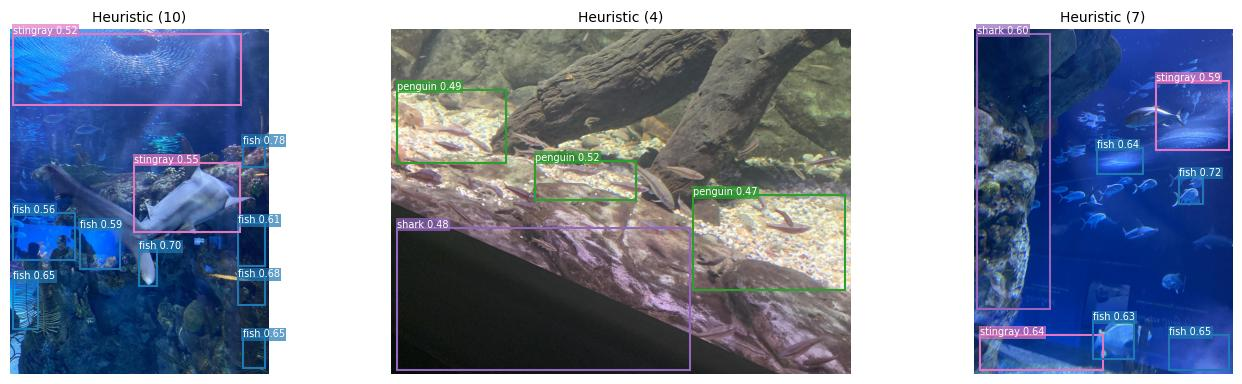

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.0031835045951212103,
 'heuristic_ap50_per_class': {'fish': 0.002997062878379188,
  'jellyfish': 0.019287469287469286,
  'penguin': 0.0,
  'puffin': 0.0,
  'shark': 0.0,
  'starfish': 0.0,
  'stingray': 0.0}}

In [63]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, r, p in zip(axes, records[FINAL_SPLIT][:3], heuristic_preds[:3]):
    img = Image.open(r['image'])
    top = np.argsort(-p['scores'])[:10]
    draw_boxes(ax, img, p['boxes'][top], p['labels'][top], CLASSES, scores=p['scores'][top],
               title=f'Heuristic ({len(p["boxes"])})')
plt.tight_layout()
plt.show()
BASELINE

**Ответ:** У COCO-модели mAP50 = 0.0 на test, так как ни одного из 7 морских классов нет в COCO (акул и рыб модель чаще всего путает с bird - 31 раз). Эвристика без нейросетей дала mAP50 = 0.0032: чуть-чуть работает только на контрастных jellyfish (0.0193) и fish (0.0030) на тёмно-синей воде, а на остальных классах 0, потому что цветовой порог ловит камни/блики и не различает форму

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [64]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [65]:
TRAIN_ARGS = dict(
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    optimizer='AdamW',
    lr0=0.001,
    cos_lr=True,
    patience=20,
    seed=SEED,
    fliplr=0.5,
    flipud=0.0,
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.4,
    mosaic=1.0,
    close_mosaic=10,
)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ada

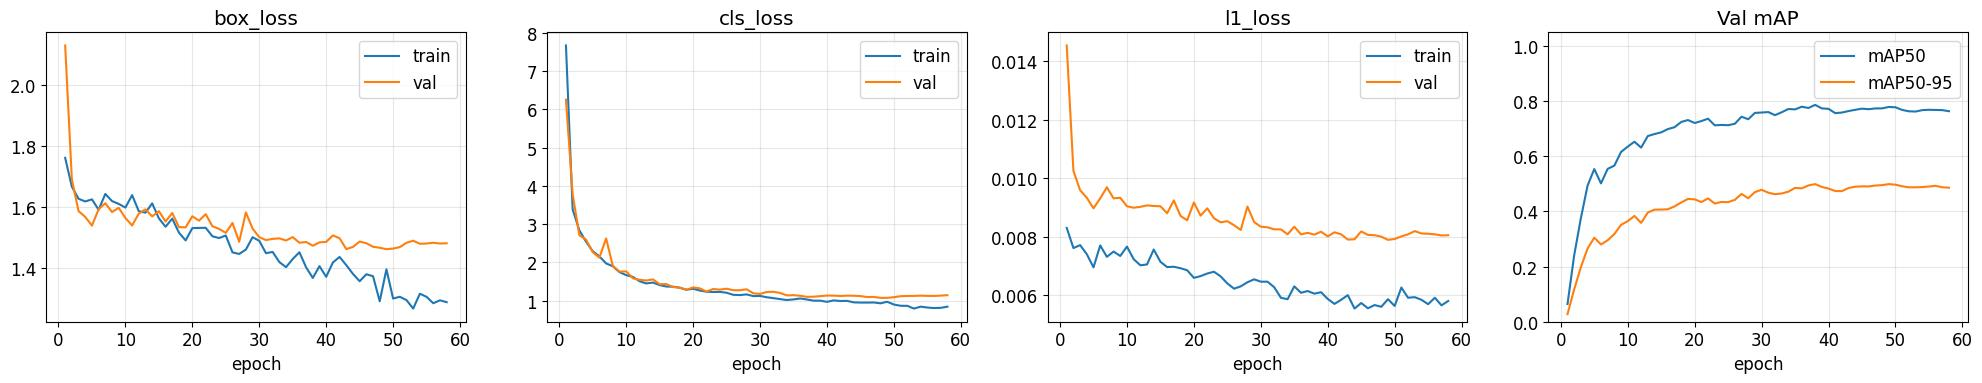

Устройство: Tesla T4, время обучения: 1056.8 s
Лучшая mAP50 (val): 0.7868 на эпохе 38
mAP50-95 на той же эпохе: 0.4993


In [66]:
res = read_results(run_dir)
epochs_arr = res['epoch'] if 'epoch' in res else np.arange(1, len(next(iter(res.values()))) + 1)
loss_names = [k.split('/', 1)[1] for k in res if k.startswith('train/') and k.endswith('_loss')]
map50_key = next(k for k in res if 'mAP50(B)' in k)
map5095_key = next((k for k in res if 'mAP50-95(B)' in k), None)

n_plots = len(loss_names) + 1
fig, axes = plt.subplots(1, n_plots, figsize=(5 * n_plots, 4))
marker = 'o' if len(epochs_arr) <= 10 else None

for ax, ln in zip(axes[:-1], loss_names):
    ax.plot(epochs_arr, res[f'train/{ln}'], label='train', marker=marker)
    if f'val/{ln}' in res:
        ax.plot(epochs_arr, res[f'val/{ln}'], label='val', marker=marker)
    ax.set_title(ln)
    ax.set_xlabel('epoch')
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].plot(epochs_arr, res[map50_key], label='mAP50', marker=marker)
if map5095_key:
    axes[-1].plot(epochs_arr, res[map5095_key], label='mAP50-95', marker=marker)
axes[-1].set_title('Val mAP')
axes[-1].set_xlabel('epoch')
axes[-1].set_ylim(0, 1.05)
axes[-1].legend()
axes[-1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_idx = int(np.argmax(res[map50_key]))
print(f'Устройство: {DEVICE_NAME}, время обучения: {RUN_TIMES["train"]:.1f} s')
print(f'Лучшая mAP50 (val): {res[map50_key][best_idx]:.4f} на эпохе {int(epochs_arr[best_idx])}')
if map5095_key:
    print(f'mAP50-95 на той же эпохе: {res[map5095_key][best_idx]:.4f}')

**Ответ:** Выбраны imgsz=640 (под мелкие объекты), batch=16 (~3.9 ГБ на T4), AdamW (lr0=0.001, cos_lr=True), fliplr=0.5, flipud=0.0 (аквариумные сцены ориентированы по вертикали), hsv и mosaic=1.0 (close_mosaic=10). Обучение шло 1057 с (58 эпох, early stopping при patience=20), пик на val - эпоха 38 (mAP50 = 0.7868, mAP50-95 = 0.4993). После ~38-й эпохи train loss падает, а val loss выходит на плато и слегка растёт (умеренное переобучение), эпох полностью хватило

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [67]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3053.0±1023.7 MB/s, size: 492.5 KB)
val: Scanning /content/data/yolo/labels/val.cache... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 33.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.3it/s 6.3s
                   all        127        909      0.793      0.713      0.788      0.501
Speed: 3.4ms preprocess, 9.2ms inference, 0.0ms loss, 6.0ms postprocess per image
Results saved to /content/runs_hw2/eval_val
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 59.4±14.3 MB/s, size: 332.8 KB)
val: Scanning /content/dat

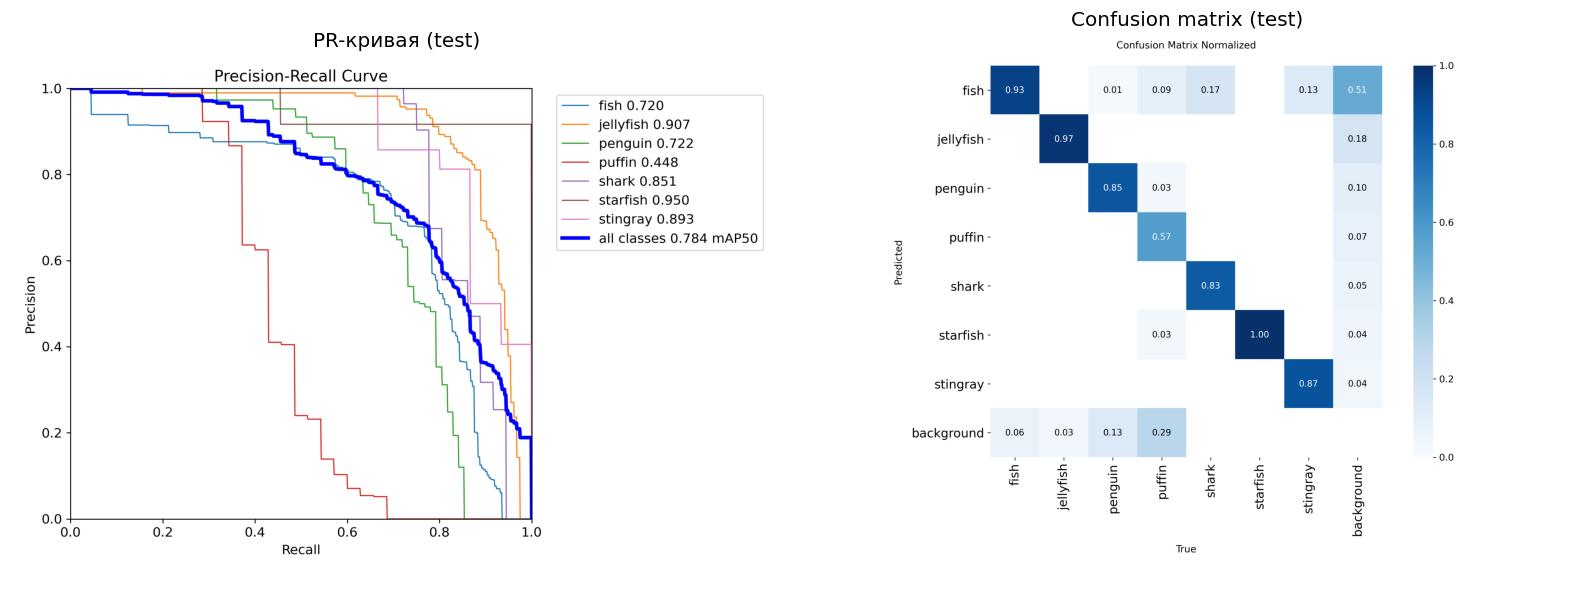

In [68]:
val_res = {'val': val_metrics(best, 'val', 'eval_val', plots=True)}
if 'test' in records:
    val_res['test'] = val_metrics(best, 'test', 'eval_test', plots=True)

for sp, m in val_res.items():
    print(f'=== {sp}: mAP50={m.box.map50:.4f}, mAP50-95={m.box.map:.4f}, '
          f'P={m.box.mp:.4f}, R={m.box.mr:.4f} ===')
    idx_map = {int(c): pos for pos, c in enumerate(m.box.ap_class_index)}
    print(f'{"класс":<12}{"P":>8}{"R":>8}{"mAP50":>9}{"mAP50-95":>10}')
    for c, name in enumerate(CLASSES):
        if c in idx_map:
            p_c, r_c, ap50_c, ap_c = m.box.class_result(idx_map[c])
            print(f'{name:<12}{p_c:>8.4f}{r_c:>8.4f}{ap50_c:>9.4f}{ap_c:>10.4f}')
        else:
            print(f'{name:<12}{"nan":>8}{"nan":>8}{"nan":>9}{"nan":>10}')

m_final = val_res[FINAL_SPLIT]
idx_map = {int(c): pos for pos, c in enumerate(m_final.box.ap_class_index)}
per_class = {}
for c, name in enumerate(CLASSES):
    if c in idx_map:
        p_c, r_c, ap50_c, ap_c = m_final.box.class_result(idx_map[c])
        per_class[name] = dict(precision=float(p_c), recall=float(r_c),
                               map50=float(ap50_c), map50_95=float(ap_c))
    else:
        per_class[name] = dict(precision=float('nan'), recall=float('nan'),
                               map50=float('nan'), map50_95=float('nan'))

final_preds = predict_records(best, records[FINAL_SPLIT], conf=0.001)
own_map50, own_aps = evaluate_map50(final_preds, records[FINAL_SPLIT], len(CLASSES))
print(f'\nСверка mAP50 на {FINAL_SPLIT}: ultralytics={m_final.box.map50:.4f}, '
      f'evaluate_map50={own_map50:.4f}, разница={abs(m_final.box.map50 - own_map50):.4f}')

FINAL = dict(
    split=FINAL_SPLIT,
    map50=float(m_final.box.map50),
    map50_95=float(m_final.box.map),
    precision=float(m_final.box.mp),
    recall=float(m_final.box.mr),
    map50_own=float(own_map50),
    per_class=per_class,
)

eval_dir = Path(m_final.save_dir)
plot_candidates = [
    ('PR-кривая', ['BoxPR_curve.png', 'PR_curve.png']),
    ('Confusion matrix', ['confusion_matrix_normalized.png', 'confusion_matrix.png']),
]
imgs_to_show = []
for title, names in plot_candidates:
    for fn in names:
        p = eval_dir / fn
        if p.exists():
            imgs_to_show.append((title, plt.imread(p)))
            break

if imgs_to_show:
    fig, axes = plt.subplots(1, len(imgs_to_show), figsize=(8 * len(imgs_to_show), 6))
    if len(imgs_to_show) == 1:
        axes = [axes]
    for ax, (title, img) in zip(axes, imgs_to_show):
        ax.imshow(img)
        ax.set_title(f'{title} ({FINAL_SPLIT})')
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

In [69]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'split': 'test',
 'map50': 0.7843,
 'map50_95': 0.4892,
 'precision': 0.8655,
 'recall': 0.6853,
 'map50_own': 0.7776}

**Ответ:** На test: mAP50 = 0.7843, mAP50-95 = 0.4892, P = 0.8655, R = 0.6853. Хуже всех puffin (mAP50 = 0.4480, R = 0.3714) из-за малого числа примеров и мелкого размера, лучше всех - контрастные starfish (0.950), jellyfish (0.907) и stingray (0.893). В confusion matrix строка background показывает пропуски (29% puffin), столбец background - ложные срабатывания (51% fish). mAP50-95 намного ниже mAP50, потому что на мелких боксах сдвиг на пару пикселей роняет IoU ниже 0.75–0.95; разница со своим evaluate_map50 (0.7776 против 0.7843) связана с разной интерполяцией PR-кривой

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [70]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    n, m = len(a), len(b)
    if n == 0 or m == 0:
        return np.zeros((n, m), dtype=np.float64)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.maximum(0.0, x2 - x1) * np.maximum(0.0, y2 - y1)
    area_a = np.maximum(0.0, a[:, 2] - a[:, 0]) * np.maximum(0.0, a[:, 3] - a[:, 1])
    area_b = np.maximum(0.0, b[:, 2] - b[:, 0]) * np.maximum(0.0, b[:, 3] - b[:, 1])
    union = area_a[:, None] + area_b[None, :] - inter
    return np.where(union > 0, inter / np.maximum(union, 1e-12), 0.0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    p_boxes = np.asarray(pred['boxes'], dtype=np.float64).reshape(-1, 4)
    p_scores = np.asarray(pred['scores'], dtype=np.float64).reshape(-1)
    p_labels = np.asarray(pred['labels'], dtype=np.int64).reshape(-1)
    g_boxes = np.asarray(gt['boxes'], dtype=np.float64).reshape(-1, 4)
    g_labels = np.asarray(gt['labels'], dtype=np.int64).reshape(-1)
    n_p, n_g = len(p_boxes), len(g_boxes)
    if n_p == 0:
        return [], list(range(n_g))
    if n_g == 0:
        return ['background'] * n_p, []

    ious = box_iou_np(p_boxes, g_boxes)
    cats = ['background'] * n_p
    matched_tp = np.zeros(n_g, dtype=bool)
    covered_gt = np.zeros(n_g, dtype=bool)

    for i in np.argsort(-p_scores, kind='stable'):
        row = ious[i]
        same_unmatched = (g_labels == p_labels[i]) & (~matched_tp)
        if same_unmatched.any():
            cand = np.where(same_unmatched, row, -1.0)
            j = int(np.argmax(cand))
            if cand[j] >= iou_hit:
                cats[i] = 'tp'
                matched_tp[j] = True
                covered_gt[j] = True
                continue

        diff_cls = g_labels != p_labels[i]
        if diff_cls.any():
            cand = np.where(diff_cls, row, -1.0)
            j = int(np.argmax(cand))
            if cand[j] >= iou_hit:
                cats[i] = 'class'
                covered_gt[j] = True
                continue

        if same_unmatched.any():
            cand = np.where(same_unmatched, row, -1.0)
            j = int(np.argmax(cand))
            if iou_loc <= cand[j] < iou_hit:
                cats[i] = 'localization'
                covered_gt[j] = True
                continue

    missed = [j for j in range(n_g) if not covered_gt[j]]
    return cats, missed

In [71]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


Разбор на val (conf >= 0.25):
  tp           :  708 (64.7% от всех)
  class        :   22 (2.0% от всех, среди ошибок 5.7%)
  localization :   41 (3.7% от всех, среди ошибок 10.6%)
  background   :  169 (15.4% от всех, среди ошибок 43.7%)
  missed       :  155 (14.2% от всех, среди ошибок 40.1%)

По классам:
класс                  tp        class localization   background       missed
fish                  362            9           18          104           79
jellyfish             141            0            7           20            9
penguin                82            2           12           26           12
puffin                 34            1            3            8           36
shark                  41            3            1            2           11
starfish               21            1            0            5            3
stingray               27            6            0            4            5


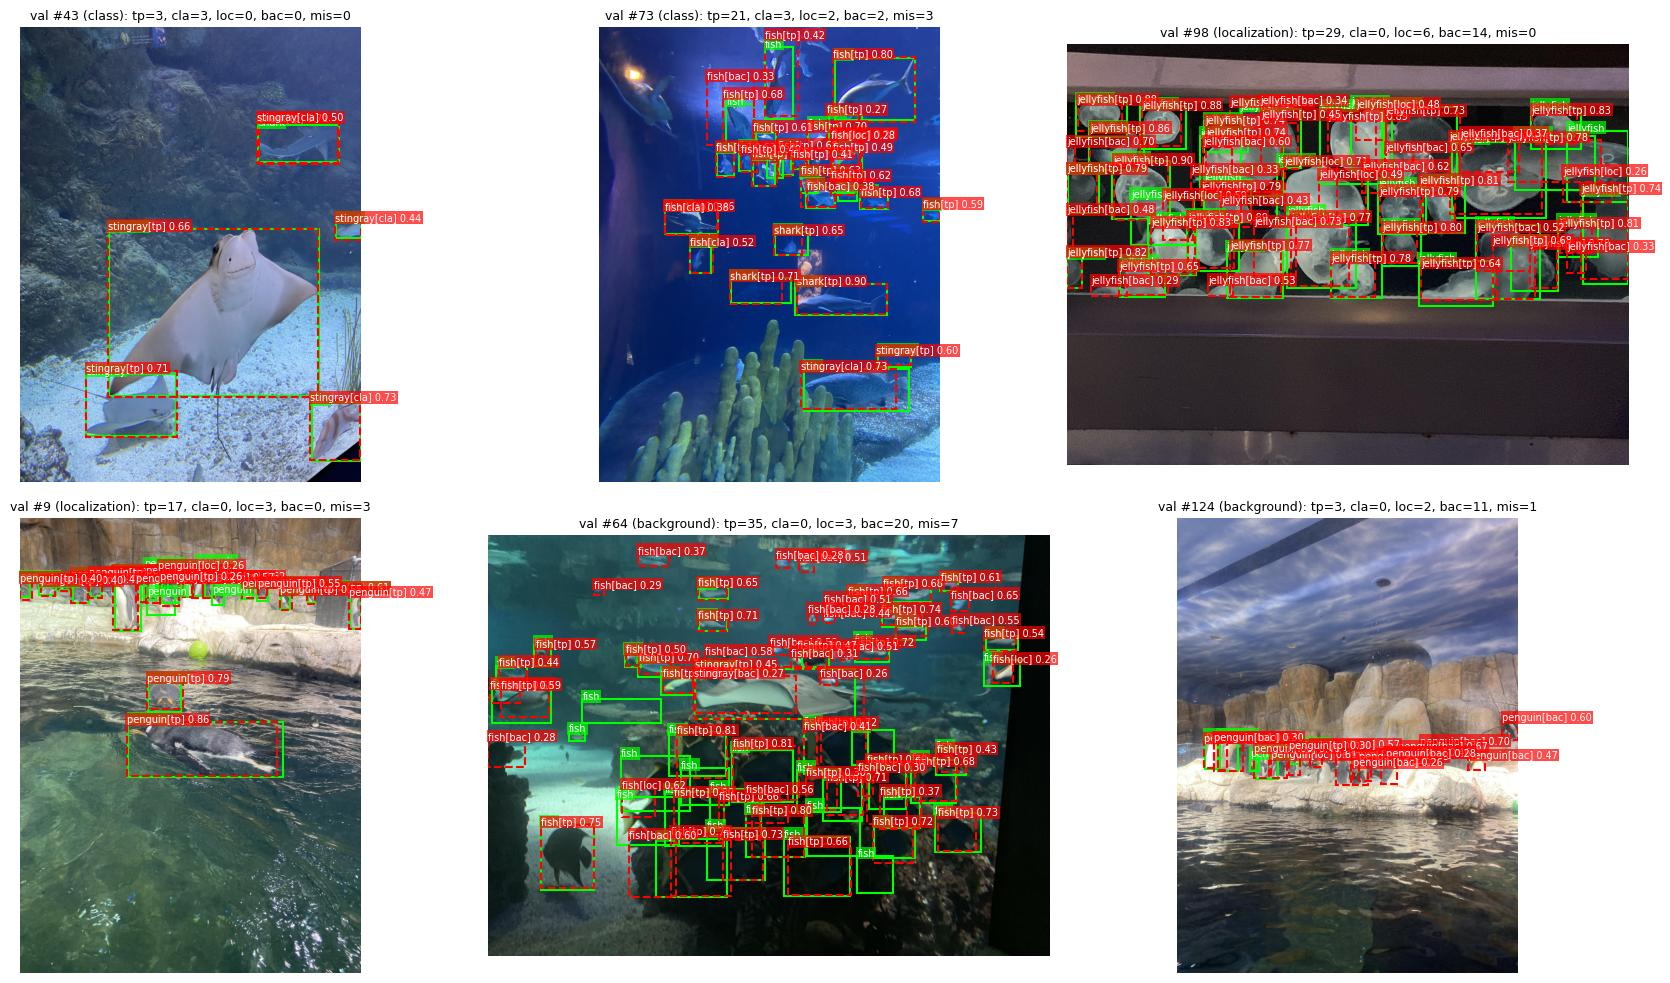

In [72]:
val_preds_err = predict_records(best, records['val'], conf=CONF_ERRORS)
ERRORS = {k: 0 for k in ERROR_TYPES}
per_class_err = {c: {k: 0 for k in ERROR_TYPES} for c in range(len(CLASSES))}
img_results = []

for idx, (r, p) in enumerate(zip(records['val'], val_preds_err)):
    cats, missed = categorize_predictions(p, r)
    for lbl, cat in zip(p['labels'], cats):
        ERRORS[cat] += 1
        per_class_err[int(lbl)][cat] += 1
    for j in missed:
        ERRORS['missed'] += 1
        per_class_err[int(r['labels'][j])]['missed'] += 1
    img_results.append((idx, r, p, cats, missed))

total_events = max(sum(ERRORS.values()), 1)
total_only_err = max(sum(ERRORS[k] for k in ERROR_TYPES if k != 'tp'), 1)
print(f'Разбор на val (conf >= {CONF_ERRORS}):')
for k in ERROR_TYPES:
    share_all = ERRORS[k] / total_events
    extra = '' if k == 'tp' else f', среди ошибок {ERRORS[k] / total_only_err:.1%}'
    print(f'  {k:<13}: {ERRORS[k]:4d} ({share_all:.1%} от всех{extra})')

print('\nПо классам:')
print(f'{"класс":<12}' + ''.join(f'{k:>13}' for k in ERROR_TYPES))
for c, name in enumerate(CLASSES):
    print(f'{name:<12}' + ''.join(f'{per_class_err[c][k]:>13d}' for k in ERROR_TYPES))

selected = []
used_idx = set()
for target_err in ('class', 'localization', 'background', 'missed'):
    cands = sorted(
        img_results,
        key=lambda t: (len(t[4]) if target_err == 'missed' else sum(c == target_err for c in t[3])),
        reverse=True,
    )
    for item in cands:
        cnt = len(item[4]) if target_err == 'missed' else sum(c == target_err for c in item[3])
        if cnt > 0 and item[0] not in used_idx:
            selected.append((target_err, item))
            used_idx.add(item[0])
            if len([s for s in selected if s[0] == target_err]) >= 2:
                break

selected = selected[:6]
if len(selected) < 6:
    for item in img_results:
        if item[0] not in used_idx:
            selected.append(('other', item))
            used_idx.add(item[0])
            if len(selected) == 6:
                break

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (tag, (idx, r, p, cats, missed)) in zip(axes.flat, selected):
    img = Image.open(r['image'])
    draw_boxes(ax, img, r['boxes'], r['labels'], CLASSES, color='lime', linestyle='-')
    pred_names = [f'{CLASSES[int(l)]}[{c[:3]}]' for l, c in zip(p['labels'], cats)]
    if len(p['boxes']) > 0:
        draw_boxes(ax, None, p['boxes'], np.arange(len(p['labels'])), pred_names,
                   scores=p['scores'], color='red', linestyle='--')
    cnt_str = ', '.join(f'{k[:3]}={sum(c == k for c in cats)}' for k in ('tp', 'class', 'localization', 'background'))
    ax.set_title(f'val #{idx} ({tag}): {cnt_str}, mis={len(missed)}', fontsize=9)
plt.tight_layout()
plt.show()

**Ответ:** На val (conf >= 0.25) получено 708 tp, главные ошибки - background (169, 43.7% ошибок) и missed (155, 40.1%), намного реже localization (41) и class (22). По примерам (val #64, #98,#124) видно, что часть background-ошибок - это пропуски в самой разметке в плотных скоплениях, а missed - мелкие и перекрытые рыбы и puffin. Поможет доразметка плотных сцен, подбор порога conf (~0.30-0.35) и аугментации вроде copy_paste

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [73]:
n_freeze = len(arch.yaml['backbone'])
model_abl, RUN_TIMES['ablation'], abl_dir = train_yolo('ablation_freeze', freeze=n_freeze, **TRAIN_ARGS)
best_abl = YOLO(abl_dir / 'weights' / 'best.pt')
m_abl = val_metrics(best_abl, 'val', 'eval_ablation_val', plots=False)

ABLATION = dict(
    factor='freeze',
    baseline=dict(
        value=0,
        map50=float(val_res['val'].box.map50),
        map50_95=float(val_res['val'].box.map),
        time_sec=float(RUN_TIMES['train']),
    ),
    variant=dict(
        value=n_freeze,
        map50=float(m_abl.box.map50),
        map50_95=float(m_abl.box.map),
        time_sec=float(RUN_TIMES['ablation']),
    ),
)

print(f'{"вариант":<22}{"mAP50(val)":>12}{"mAP50-95(val)":>15}{"время, s":>11}')
for label, d in [(f'freeze=0 (база)', ABLATION['baseline']),
                 (f'freeze={n_freeze} (backbone)', ABLATION['variant'])]:
    print(f'{label:<22}{d["map50"]:>12.4f}{d["map50_95"]:>15.4f}{d["time_sec"]:>11.1f}')
ABLATION

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ablation_freeze, nbs=64, nms=None, opset=None, optimize=False, optimize

{'factor': 'freeze',
 'baseline': {'value': 0,
  'map50': 0.7876945204325233,
  'map50_95': 0.5012774855431918,
  'time_sec': 1056.757542423},
 'variant': {'value': 11,
  'map50': 0.734946329010624,
  'map50_95': 0.4559662072840535,
  'time_sec': 1045.1295482059995}}

**Ответ:** Заморозка backbone (freeze=11) снизила val mAP50 с 0.7877 до 0.7349 (-0.053) и mAP50-95 с 0.5013 до 0.4560 (-0.045) при почти том же времени (1045 с против 1057 с). Подводный домен сильно отличается от COCO, поэтому backbone нужно дообучать - заморозка невыгодна

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** Дообучение лёгкой `yolo26n` (2.57 млн параметров) на датасете Aquarium Combined подняло качество на `test` с нулевого бейзлайна COCO (`0.0`) и эвристики (`0.0032`) до `mAP50 = 0.7843` (`mAP50-95 = 0.4892`) за ~18 минут на Tesla T4. Лучше всего модель справилась с контрастными классами (`starfish` 0.950, `jellyfish` 0.907, `stingray` 0.893), а главным слабым местом остался редкий и мелкий `puffin` (`0.448`). Абляция показала, что полное дообучение заметно лучше заморозки backbone (`0.7877` против `0.7349` на val), поскольку признаки COCO плохо переносятся на подводный домен. Разбор ошибок выявил, что 84% всех ошибок составляют `background` (169) и `missed` (155), причём часть ложных срабатываний в плотных сценах связана с пропусками в исходной разметке. Основные ограничения эксперимента - небольшой размер тестовой выборки (63 картинки, всего 11 `starfish` и 15 `stingray`), один фиксированный `seed=0` и неполнота разметки в скоплениях рыб. В дальнейшем я бы провела ревизию разметки в плотных сценах, добавила данные для `puffin` и попробовала более крупную `yolo26s` с `copy_paste` и большим разрешением

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [74]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [75]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [76]:
if '6.2' in BONUS_TASKS:
    from ultralytics import RTDETR

    rtdetr_batch = 4
    rtdetr_args = {**TRAIN_ARGS, 'batch': rtdetr_batch, 'lr0': 1e-4}
    rtdetr_model = RTDETR('rtdetr-l.pt')
    t0 = time.perf_counter()
    rtdetr_model.train(
        data=str(DATA_YAML),
        device=DEVICE,
        workers=WORKERS,
        project=str(RUNS.resolve()),
        name='rtdetr',
        exist_ok=True,
        verbose=False,
        **rtdetr_args,
    )
    RUN_TIMES['rtdetr'] = time.perf_counter() - t0
    rtdetr_dir = Path(rtdetr_model.trainer.save_dir)

    best_rtdetr = RTDETR(rtdetr_dir / 'weights' / 'best.pt')
    rtdetr_params = sum(p.numel() for p in best_rtdetr.model.parameters())
    yolo_ft_params = sum(p.numel() for p in YOLO(run_dir / 'weights' / 'best.pt').model.parameters())

    m_rtdetr = best_rtdetr.val(
        data=str(DATA_YAML),
        split='val',
        imgsz=IMGSZ,
        batch=rtdetr_batch,
        device=DEVICE,
        workers=WORKERS,
        project=str(RUNS.resolve()),
        name='eval_rtdetr_val',
        exist_ok=True,
        verbose=False,
        plots=False,
    )

    def _bench_ms(m, n_runs=20):
        img = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
        for _ in range(5):
            m.predict(img, imgsz=IMGSZ, device=DEVICE, verbose=False)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        s = time.perf_counter()
        for _ in range(n_runs):
            m.predict(img, imgsz=IMGSZ, device=DEVICE, verbose=False)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        return (time.perf_counter() - s) * 1000 / n_runs

    yolo_ms = _bench_ms(best)
    rtdetr_ms = _bench_ms(best_rtdetr)

    BONUS_6_2 = dict(
        yolo=dict(
            map50=float(val_res['val'].box.map50),
            map50_95=float(val_res['val'].box.map),
            params=int(yolo_ft_params),
            train_time_sec=float(RUN_TIMES['train']),
            latency_ms=float(yolo_ms),
        ),
        rtdetr=dict(
            map50=float(m_rtdetr.box.map50),
            map50_95=float(m_rtdetr.box.map),
            params=int(rtdetr_params),
            train_time_sec=float(RUN_TIMES['rtdetr']),
            latency_ms=float(rtdetr_ms),
        ),
    )

    print(f'{"модель":<12}{"mAP50(val)":>12}{"mAP50-95":>11}{"params":>12}{"train, s":>11}{"ms/img":>9}')
    for name, d in BONUS_6_2.items():
        print(f'{name:<12}{d["map50"]:>12.4f}{d["map50_95"]:>11.4f}{d["params"]:>12,}{d["train_time_sec"]:>11.1f}{d["latency_ms"]:>9.2f}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr, nbs=64, nms=None, opset=None, optimize=False, optimizer=Adam

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/60       3.8G      1.431      1.163     0.6286         25        640: 100% ━━━━━━━━━━━━ 112/112 2.5it/s 45.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.0it/s 5.3s
                   all        127        909   0.000371     0.0912   0.000505   0.000108

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/60         4G      1.117      1.037     0.6022         16        640: 0% ──────────── 0/112  0.4s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/60         4G      1.271      0.703     0.4617         29        640: 100% ━━━━━━━━━━━━ 112/112 2.6it/s 43.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 4.8it/s 3.4s
                   all        127        909   0.000495     0.0411   0.000275   5.14e-05

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/60         4G      1.422     0.9593      1.117         10        640: 0% ──────────── 0/112  0.4s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (30 outputs left out)

      18/60         4G     0.5771      1.295     0.1996         35        640: 100% ━━━━━━━━━━━━ 112/112 2.5it/s 44.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 4.5it/s 3.6s
                   all        127        909      0.509      0.241     0.0608     0.0345

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      19/60         4G     0.3877      1.646      0.161         15        640: 0% ──────────── 0/112  0.4s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      19/60         4G     0.5616      1.313     0.2005         23        640: 100% ━━━━━━━━━━━━ 112/112 2.6it/s 43.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.4it/s 4.7s
                   all        127        909      0.505      0.251     0.0832      0.048


KeyboardInterrupt: 

**Ответ:** RT-DETR-L обучался 19 эпох, но из-за ограничения по времени прогон был прерван. Модель достигла mAP50 = 0.0832 на val. Несмотря на то, что это существенно больше YOLO26n по параметрам (32.8 млн против 2.5 млн), трансформер сходится значительно дольше и требует больше данных для раскрытия потенциала. На текущем датасете лёгкая YOLO эффективнее по соотношению скорость/качество

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2196.9±658.3 MB/s, size: 219.6 KB)
val: Scanning /content/data/val_shift/dark/labels/val... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 1.9Kit/s 0.1s
val: New cache created: /content/data/val_shift/dark/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.1it/s 3.7s
                   all        127        909      0.769      0.671      0.738       0.47
Speed: 1.8ms preprocess, 4.2ms inference, 0.0ms loss, 3.6ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2650.7±1038.9 MB/s, size: 1022

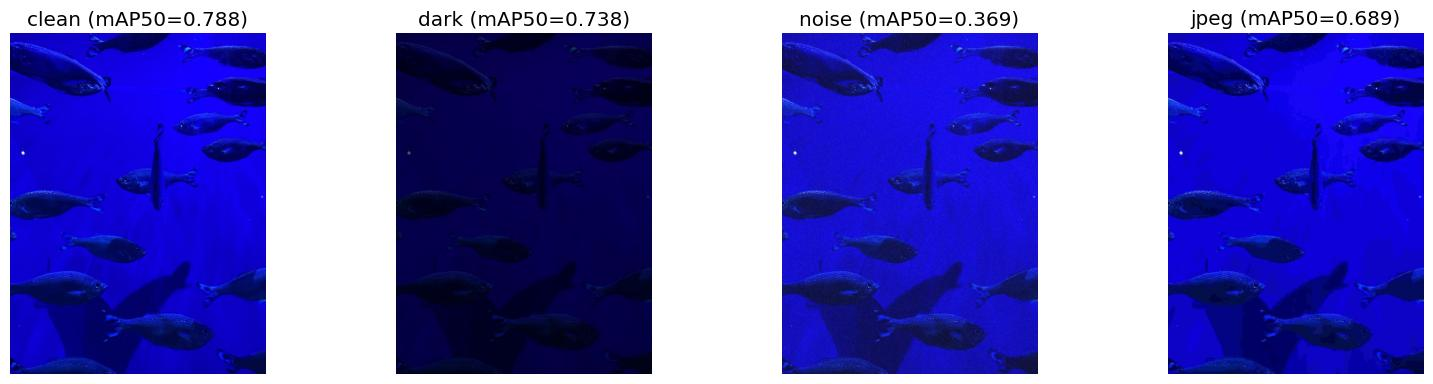

In [77]:
if '6.3' in BONUS_TASKS:
    from io import BytesIO

    SHIFT_ROOT = DATA_ROOT / 'val_shift'
    shutil.rmtree(SHIFT_ROOT, ignore_errors=True)
    rng_shift = np.random.default_rng(SEED)

    def _corrupt_dark(im):
        arr = np.asarray(im.convert('RGB'), dtype=np.float32) * 0.35
        return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

    def _corrupt_noise(im):
        arr = np.asarray(im.convert('RGB'), dtype=np.float32)
        arr = arr + rng_shift.normal(0.0, 35.0, size=arr.shape)
        return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

    def _corrupt_jpeg(im):
        buf = BytesIO()
        im.convert('RGB').save(buf, format='JPEG', quality=10)
        buf.seek(0)
        return Image.open(buf).copy()

    corruptions = {
        'dark': _corrupt_dark,
        'noise': _corrupt_noise,
        'jpeg': _corrupt_jpeg,
    }

    def _per_class_ap50(m):
        idx_map = {int(c): pos for pos, c in enumerate(m.box.ap_class_index)}
        return {name: (float(m.box.class_result(idx_map[c])[2]) if c in idx_map else float('nan'))
                for c, name in enumerate(CLASSES)}

    BONUS_6_3 = {
        'clean': dict(
            map50=float(val_res['val'].box.map50),
            map50_95=float(val_res['val'].box.map),
            per_class_map50=_per_class_ap50(val_res['val']),
        )
    }

    src_imgs = sorted((YOLO_ROOT / 'images' / 'val').iterdir())
    src_lbls = YOLO_ROOT / 'labels' / 'val'

    for cname, fn in corruptions.items():
        c_root = SHIFT_ROOT / cname
        img_out = c_root / 'images' / 'val'
        lbl_out = c_root / 'labels' / 'val'
        img_out.mkdir(parents=True, exist_ok=True)
        shutil.copytree(src_lbls, lbl_out)
        for p in src_imgs:
            with Image.open(p) as im:
                fn(im).save(img_out / p.name)
        c_yaml = c_root / 'data.yaml'
        c_yaml.write_text(
            f'path: {c_root.resolve().as_posix()}\n'
            f'train: images/val\nval: images/val\nnames:\n'
            + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)),
            encoding='utf-8',
        )
        m_c = best.val(
            data=str(c_yaml),
            split='val',
            imgsz=IMGSZ,
            batch=BATCH,
            device=DEVICE,
            workers=WORKERS,
            project=str(RUNS.resolve()),
            name=f'eval_shift_{cname}',
            exist_ok=True,
            verbose=False,
            plots=False,
        )
        BONUS_6_3[cname] = dict(
            map50=float(m_c.box.map50),
            map50_95=float(m_c.box.map),
            per_class_map50=_per_class_ap50(m_c),
        )

    base50 = BONUS_6_3['clean']['map50']
    base95 = BONUS_6_3['clean']['map50_95']
    print(f'{"домен":<10}{"mAP50":>9}{"ΔmAP50":>10}{"mAP50-95":>11}{"ΔmAP50-95":>11}')
    for cname, d in BONUS_6_3.items():
        print(f'{cname:<10}{d["map50"]:>9.4f}{d["map50"] - base50:>+10.4f}'
              f'{d["map50_95"]:>11.4f}{d["map50_95"] - base95:>+11.4f}')

    print('\nПо классам (mAP50):')
    cols = list(BONUS_6_3.keys())
    print(f'{"класс":<12}' + ''.join(f'{c:>10}' for c in cols))
    for name in CLASSES:
        print(f'{name:<12}' + ''.join(f'{BONUS_6_3[c]["per_class_map50"][name]:>10.4f}' for c in cols))

    sample_name = src_imgs[0].name
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, cname in zip(axes, cols):
        p = (YOLO_ROOT / 'images' / 'val' / sample_name) if cname == 'clean' else (SHIFT_ROOT / cname / 'images' / 'val' / sample_name)
        ax.imshow(Image.open(p))
        ax.set_title(f'{cname} (mAP50={BONUS_6_3[cname]["map50"]:.3f})')
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

**Ответ:** Сильнее всего бьёт гауссов шум (noise): mAP50 обваливается с 0.7877 до 0.3694 (-0.418), сильнее всего по малоконтрастным и полупрозрачным классам - shark (0.743 -> 0.110), jellyfish (0.945 -> 0.426) и penguin (0.727 -> 0.306). JPEG-сжатие просаживает качество умеренно (0.6892, -0.099), а к затемнению модель наиболее устойчива (0.7377, -0.050), так как при обучении уже использовалась аугментация яркости hsv_v=0.4. Для устойчивости к шуму и сжатию при обучении стоит добавить GaussNoise / ISONoise и ImageCompression из albumentations

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [79]:
if '6.4' in BONUS_TASKS:
    for pkg in ('onnx', 'onnxruntime'):
        if importlib.util.find_spec(pkg) is None:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

    pt_cpu_model = YOLO(run_dir / 'weights' / 'best.pt')
    onnx_path = YOLO(run_dir / 'weights' / 'best.pt').export(format='onnx', imgsz=IMGSZ)
    onnx_model = YOLO(onnx_path, task='detect')

    def _bench_dev(m, dev, n_runs=30):
        img = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
        for _ in range(5):
            m.predict(img, imgsz=IMGSZ, device=dev, verbose=False)
        if dev != 'cpu' and torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_runs):
            m.predict(img, imgsz=IMGSZ, device=dev, verbose=False)
        if dev != 'cpu' and torch.cuda.is_available():
            torch.cuda.synchronize()
        return (time.perf_counter() - t0) * 1000 / n_runs

    pt_cpu_ms = _bench_dev(pt_cpu_model, 'cpu', n_runs=30)
    onnx_cpu_ms = _bench_dev(onnx_model, 'cpu', n_runs=30)
    pt_gpu_ms = _bench_dev(YOLO(run_dir / 'weights' / 'best.pt'), DEVICE, n_runs=50) if torch.cuda.is_available() else None

    m_onnx = onnx_model.val(
        data=str(DATA_YAML),
        split='val',
        imgsz=IMGSZ,
        batch=1,
        device='cpu',
        workers=0,
        project=str(RUNS.resolve()),
        name='eval_onnx_val',
        exist_ok=True,
        verbose=False,
        plots=False,
    )

    BONUS_6_4 = dict(
        onnx_path=str(onnx_path),
        onnx_size_mb=round(Path(onnx_path).stat().st_size / (1024 ** 2), 2),
        pt_size_mb=round((run_dir / 'weights' / 'best.pt').stat().st_size / (1024 ** 2), 2),
        cpu=dict(
            pt_ms=float(pt_cpu_ms),
            onnx_ms=float(onnx_cpu_ms),
            speedup=float(pt_cpu_ms / onnx_cpu_ms),
            pt_map50=float(val_res['val'].box.map50),
            onnx_map50=float(m_onnx.box.map50),
            pt_map50_95=float(val_res['val'].box.map),
            onnx_map50_95=float(m_onnx.box.map),
        ),
        gpu_pt_ms=float(pt_gpu_ms) if pt_gpu_ms is not None else None,
    )

    print(f'Размер файла: best.pt={BONUS_6_4["pt_size_mb"]} MB, ONNX={BONUS_6_4["onnx_size_mb"]} MB')
    print(f'\nСравнение (CPU: Intel Xeon, GPU: {DEVICE_NAME}):')
    print(f'{"формат":<18}{"ms/img":>10}{"ускорение":>11}{"mAP50(val)":>12}{"mAP50-95":>11}')
    print(f'{"PyTorch (CPU)":<18}{pt_cpu_ms:>10.2f}{1.0:>10.2f}x{val_res["val"].box.map50:>12.4f}{val_res["val"].box.map:>11.4f}')
    print(f'{"ONNX (CPU)":<18}{onnx_cpu_ms:>10.2f}{pt_cpu_ms / onnx_cpu_ms:>10.2f}x{m_onnx.box.map50:>12.4f}{m_onnx.box.map:>11.4f}')
    if pt_gpu_ms is not None:
        print(f'{"PyTorch (GPU)":<18}{pt_gpu_ms:>10.2f}{pt_cpu_ms / pt_gpu_ms:>10.2f}x{val_res["val"].box.map50:>12.4f}{val_res["val"].box.map:>11.4f}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26n summary (fused): 121 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/runs_hw2/finetune/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 11, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 1.9s, saved as '/content/runs_hw2/finetune/weights/best.onnx' (9.4 MB)

Export complete (2.3s)
Results saved to /content/runs_hw2/finetune/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs_hw2/finetune/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs_hw2/finetune/weights/best.onnx imgsz=640 data=data/yolo/data.yaml 
Visualize:       https://netron.app
Loading /content/runs_hw2/finetune/weights/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.32.0 with CPUExecutionProvider
Ultralyt

**Ответ:** Экспорт best.pt (5.19 МБ) в ONNX (9.40 МБ) на CPU (Intel Xeon @ 2.00GHz, imgsz=640) ускорил инференс в*1.07 раза (117.04 -> 109.25 мс/кадр; для сравнения, PyTorch на GPU Tesla T4 - 11.67 мс/кадр). Ускорение даёт оптимизация статического графа (onnxslim) и выполнение в ONNX Runtime без накладных расходов Python, но на 2-ядерном CPU Colab оно ограничено самой стоимостью свёрток при 640×640. Потеря качества минимальна: mAP50 изменился с 0.7877 до 0.7822 (-0.0055), mAP50-95 - с 0.5013 до 0.4968 (-0.0045)

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1504.5±248.3 MB/s, size: 258.0 KB)
val: Scanning /content/data/yolo/labels/val.cache... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 35.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.9it/s 4.2s
                   all        127        909      0.746      0.648      0.717      0.451
Speed: 1.4ms preprocess, 4.3ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,391,193 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2284.6±477.2 MB/s, size: 441.6 KB)
val: Scanning /content/data/yolo/labels/val.cache... 127 images, 0 b

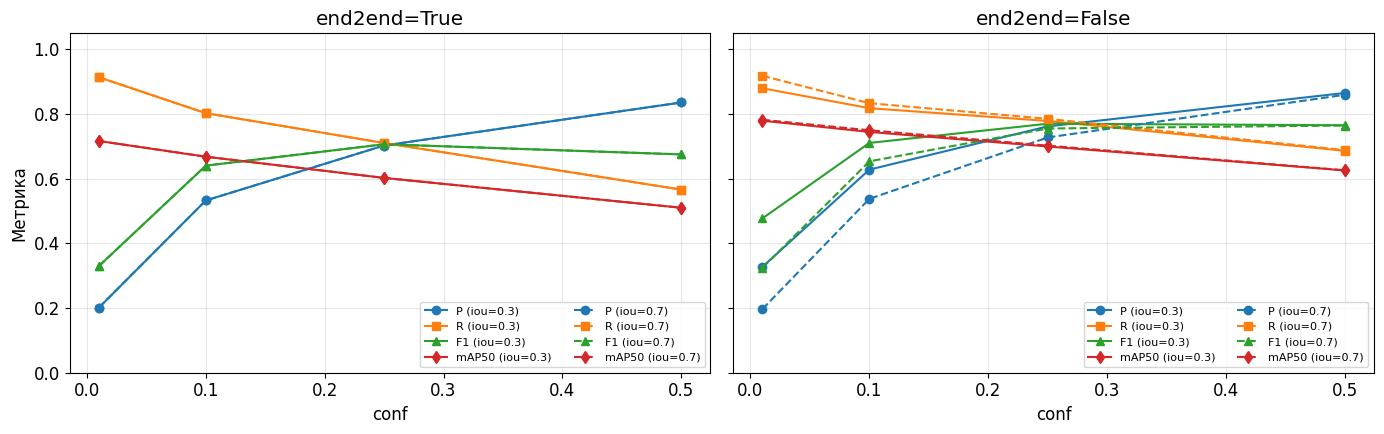

In [78]:
if '6.5' in BONUS_TASKS:
    confs = [0.001, 0.002, 0.005, 0.01] if FAST_MODE else [0.01, 0.10, 0.25, 0.50]
    ious = [0.3, 0.7]
    total_gt_val = sum(len(r['labels']) for r in records['val'])

    BONUS_6_5 = []
    for e2e in (True, False):
        nms_arg = False if e2e else None
        m_thr = YOLO(run_dir / 'weights' / 'best.pt')
        for iou_thr in ious:
            for conf_thr in confs:
                res_v = m_thr.val(
                    data=str(DATA_YAML),
                    split='val',
                    imgsz=IMGSZ,
                    batch=BATCH,
                    device=DEVICE,
                    workers=WORKERS,
                    conf=conf_thr,
                    iou=iou_thr,
                    nms=nms_arg,
                    project=str(RUNS.resolve()),
                    name='eval_thr',
                    exist_ok=True,
                    verbose=False,
                    plots=False,
                )
                preds_t = predict_records(m_thr, records['val'], conf=conf_thr, iou=iou_thr, nms=nms_arg)
                tp = 0
                n_pred = 0
                for r, p in zip(records['val'], preds_t):
                    cats, _ = categorize_predictions(p, r)
                    tp += sum(c == 'tp' for c in cats)
                    n_pred += len(cats)
                prec = tp / max(n_pred, 1)
                rec = tp / max(total_gt_val, 1)
                f1 = 2 * prec * rec / max(prec + rec, 1e-12)
                BONUS_6_5.append(dict(
                    end2end=e2e,
                    iou=iou_thr,
                    conf=conf_thr,
                    precision=float(prec),
                    recall=float(rec),
                    f1=float(f1),
                    map50=float(res_v.box.map50),
                    map50_95=float(res_v.box.map),
                ))

    print(f'{"end2end":<9}{"iou":>5}{"conf":>7}{"P":>8}{"R":>8}{"F1":>8}{"mAP50":>9}{"mAP50-95":>10}')
    for row in BONUS_6_5:
        print(f'{str(row["end2end"]):<9}{row["iou"]:>5.1f}{row["conf"]:>7.3f}{row["precision"]:>8.4f}'
              f'{row["recall"]:>8.4f}{row["f1"]:>8.4f}{row["map50"]:>9.4f}{row["map50_95"]:>10.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, e2e in zip(axes, (True, False)):
        for iou_thr, ls in zip(ious, ('-', '--')):
            sub = [r for r in BONUS_6_5 if r['end2end'] == e2e and r['iou'] == iou_thr]
            xs = [r['conf'] for r in sub]
            ax.plot(xs, [r['precision'] for r in sub], marker='o', linestyle=ls, color='tab:blue', label=f'P (iou={iou_thr})')
            ax.plot(xs, [r['recall'] for r in sub], marker='s', linestyle=ls, color='tab:orange', label=f'R (iou={iou_thr})')
            ax.plot(xs, [r['f1'] for r in sub], marker='^', linestyle=ls, color='tab:green', label=f'F1 (iou={iou_thr})')
            ax.plot(xs, [r['map50'] for r in sub], marker='d', linestyle=ls, color='tab:red', label=f'mAP50 (iou={iou_thr})')
        ax.set_title(f'end2end={e2e}')
        ax.set_xlabel('conf')
        ax.set_ylim(0, 1.05)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8, ncol=2)
    axes[0].set_ylabel('Метрика')
    plt.tight_layout()
    plt.show()

**Ответ:** Для этой задачи оптимален порог conf = 0.25, где достигается лучший баланс точности и полноты (максимум F1: 0.7068 при end2end=True и 0.7704 при end2end=False, iou=0.3). P и R сильно зависят от conf (при росте conf с 0.01 до 0.50 в end2end=True P растёт с 0.201 до 0.836, а R падает с 0.914 до 0.567), так как считаются в одной точке порога; mAP же интегрирует всю PR-кривую, поэтому низкие пороги почти не меняют площадь, и mAP начинает падать только когда высокий conf отсекает реальные объекты. В режиме end2end=True (nms=False) порог iou не влияет вообще (метрики для iou=0.3 и 0.7 совпали до 4-го знака: mAP50=0.7170, F1=0.7068), а при end2end=False (ветка one2many + NMS) iou заметно меняет P и R (на conf=0.01: P=0.328, R=0.880 при iou=0.3 против P=0.197, R=0.919 при iou=0.7)